# 01 | What does the MVP actually do?

**6 minutes | Core question: How do images become actions, and which parts have been implemented?**

Read the narrative and saved outputs directly. Code cells provide optional CPU checks. Evidence snapshot: October 15, 2026.

![SFT initializes a policy; native WorldGym generates future observations; a VLM scores trajectories; GRPO updates policy weights; separate MuJoCo evaluation checks success.](media/figures/01_system.png)

[Open the full-size teaching image](media/figures/01_system.png). AI-generated schematic; actual experiment images and numerical evidence appear below.

**How to read the image:** Follow steps 1 to 4 to see how an attempt becomes a policy update. Then inspect the separate evaluation lane below. Imagined success and physical-simulation success are different measurements.

> **Remember:** Native model-based RL has already been run. Implementing the loop and establishing a policy gain are separate achievements.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'briefing_utils.py').exists())
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
get_ipython().run_line_magic('matplotlib', 'inline')
from briefing_utils import *
assert verify_assets() > 0

## The project in one sentence

This is a reproducible research testbed for a **wet-lab-inspired test-tube pickup task in MuJoCo**: learn a policy from demonstrations, evaluate and train it using a world model, then return to physics simulation to measure task success.

**Native WorldGym rollouts, VLM rewards and actual policy updates have already been implemented and run. A reliable policy improvement has not been established.** Model-based RL is therefore not a missing implementation step.

The scope is one task, 10 rack slots and perturbed initial joints. A set of 100 scenes means 100 initial conditions for this task, not 100 different tasks. There are no real-robot or real wet-lab results.

## What goes in, and what comes out?

The saved observation below contains a front-camera view and a wrist-camera view. The policy also receives joint state; the SmolVLA branch receives a task instruction. It predicts an action chunk with 50 time steps, each containing six absolute joint targets and one gripper control.

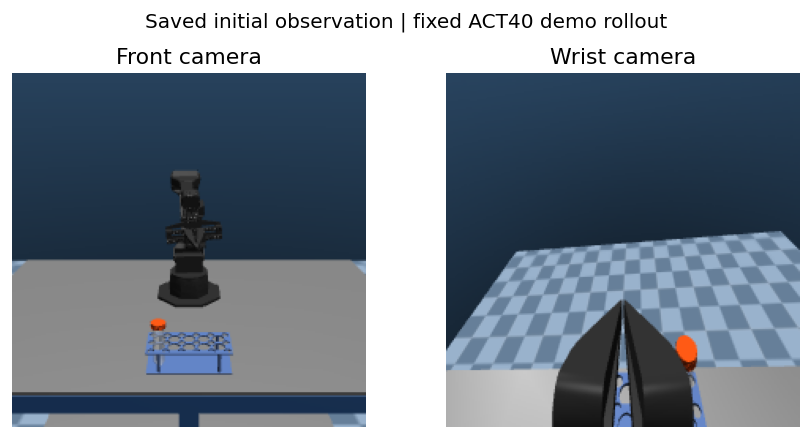

In [2]:
input_views()

## From imitation to evaluation to learning

**Supervised fine-tuning (SFT)** teaches the policy to imitate demonstrated actions. **Policy evaluation** runs a fixed policy and measures how well it behaves. **Reinforcement learning (RL)** uses rewards to change the policy's weights.

In the native loop, WorldGym generates the policy's future visual observations. A **vision-language model (VLM)** reads images and a task description to score imagined trajectories. **Group Relative Policy Optimization (GRPO)** uses relative scores within a group to change action probabilities. A separate MuJoCo evaluation measures official task success.

The diagram below describes the SmolVLA native-RL branch. ACT is used in the earlier policy experiments and as a strong reference.

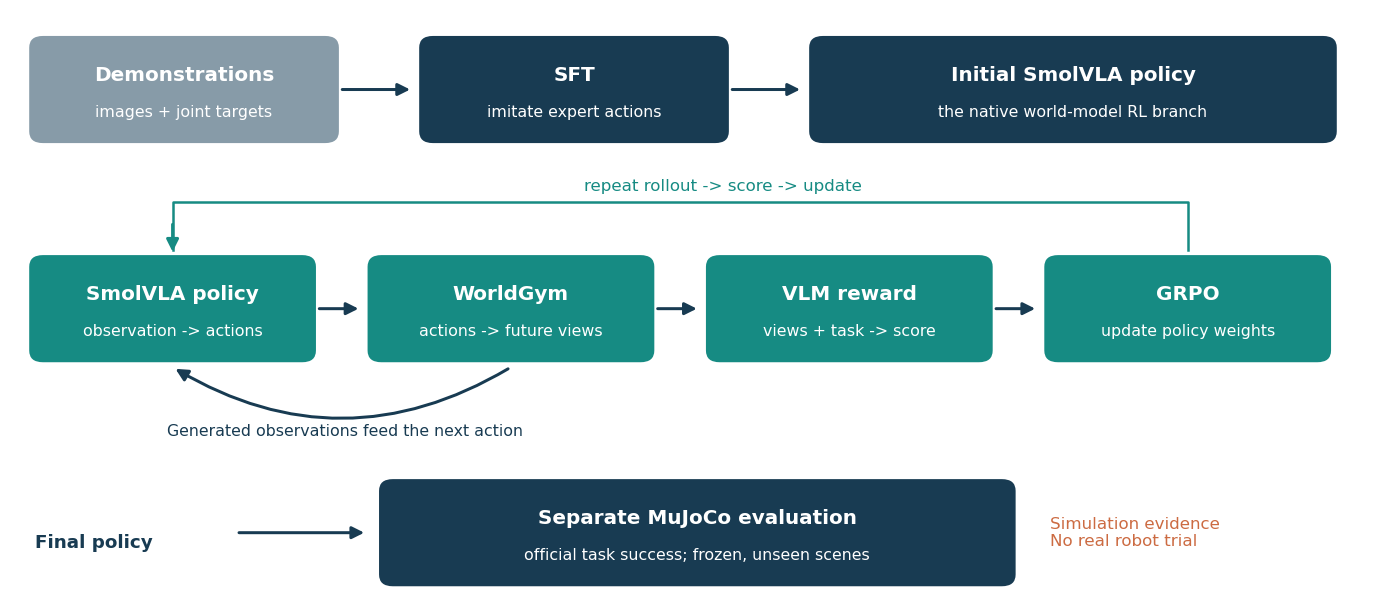

In [3]:
pipeline()

Executable core: [SFT](Scripts/sft.py), [ACT SFT](Scripts/sft_act.py), [evaluation](Scripts/evaluate.py), and [native RL](Scripts/train_native_rl.py). Shared [environment](Scripts/runtime/environment_runtime.py), [trajectory](Scripts/runtime/trajectory_runtime.py), and [GRPO](Scripts/runtime/train_grpo.py) modules are included. See [reproduction commands and external asset requirements](Scripts/README.md). This portable source release is distinct from the archived full experiments; task weights are not yet published. [SOURCE_MANIFEST](SOURCE_MANIFEST.json) records the evidence provenance.
